(quality_control)=

# Quality control and doublet detection

Filter 5,025 peripheral blood mononuclear cells (PBMCs) from a healthy human donor, the 10x Genomics 5k PBMC dataset, in two ways: with automatic bounds set from the spread of each QC measure, and with the manual thresholds of [the PBMC analysis](scrna_seq.ipynb). Then check which cell types each filter removes, and score doublets among the cells that pass the manual thresholds. The automatic bounds keep 4,331 cells and the manual thresholds 3,948. The two filters disagree at both ends of the count range: the manual thresholds remove 415 cells that the automatic bounds keep, mostly monocytes above the cap of 15,000 counts, and the automatic bounds remove 32 cells that the manual thresholds keep, among them 9 of the 12 platelets that pass the manual thresholds. Doublet scoring calls 17 of the 3,948 cells doublets, 8 of them in the CD14 monocyte cluster.

Each filter saves its result as a cell selection: an artifact that records which cells pass, together with the inputs and parameters that produced it. Filters leave the counts and the cell table unchanged, so every filter here starts from the same input cells and the counts are imported once.

## Import the counts

The counts come from the 10x Genomics dataset "5k Peripheral blood mononuclear cells (PBMCs) from a healthy donor (v3 chemistry)", released under CC BY 4.0. The file holds only the barcodes that Cell Ranger called as cells. An unfiltered droplet matrix needs cell calling first, as [the cell calling tutorial](cell_calling.ipynb) shows. The RNA {term}`pipeline recipe`, `ds.pipeline.rna`, which runs the whole RNA analysis in one call, calls and filters cells in the same run with `cell_calling=True`. The example writes its store to a temporary directory; use a project directory to keep it.

In [1]:
# Tabulate the QC values and draw the figures that compare the filters.
from contextlib import closing
from pathlib import Path
from tempfile import TemporaryDirectory

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.lines import Line2D

import cytearc
from cytearc.plotting import CellField

# Keep routine logs and progress bars out of the page.
cytearc.configure_output(level="WARNING", progress=False)

# Download the 18 MB count file of the 5k PBMC dataset.
counts = cytearc.datasets.connect("cytearc_docs").download(
    "tenx_5K_pbmc_rnaseq/data.h5",
    destination="cytearc_datasets",
)[0]

# Write the counts to a new store in a temporary directory.
workspace = TemporaryDirectory()
store = Path(workspace.name) / "quality_control.zarr"
cytearc.CrToZarr(cytearc.CrH5Reader(str(counts)), zarr_loc=str(store)).dump()

# Open the store, which computes the QC columns of every cell.
ds = cytearc.DataStore(str(store), nthreads=4, min_features_per_cell=10)
ds

DataStore has 5025 (5025) cells with 1 assays: RNA
   Cell metadata:
            'I', 'ids', 'names', 'RNA_nCounts', 'RNA_nFeatures', 
            'RNA_percentMito', 'RNA_percentRibo'
   RNA assay has 33538 features and following metadata:
            'I', 'ids', 'names', 'dropOuts', 'feature_type', 
            'genome', 'nCells'

Started: 2026-11-12T17:28:46.202657Z | Wall time: 11.637 s

Opening a new store computes four QC columns for every cell: its total counts (`RNA_nCounts`), its detected genes (`RNA_nFeatures`), and the percentages of its counts from mitochondrial genes (`RNA_percentMito`) and from ribosomal protein genes (`RNA_percentRibo`). The first open also removes every cell with 10 or fewer detected genes from the {term}`cell key` `I`, the boolean column marking the cells that analyses use by default. No cell here has so few genes, so `I` keeps all 5,025 cells.

## Inspect the QC distributions

Freeze the cells of `I` into a cell selection, a fixed copy that later changes to `I` do not affect, and use it as the input of every filter below. Then summarize and plot the four columns:

,RNA_nCounts,RNA_nFeatures,RNA_percentMito,RNA_percentRibo
min,502.0,38.0,0.0,0.7
25%,6079.0,1816.0,7.0,17.1
50%,7803.0,2171.0,8.4,28.3
75%,10210.0,2645.0,10.5,37.6
max,46913.0,6160.0,96.8,52.2


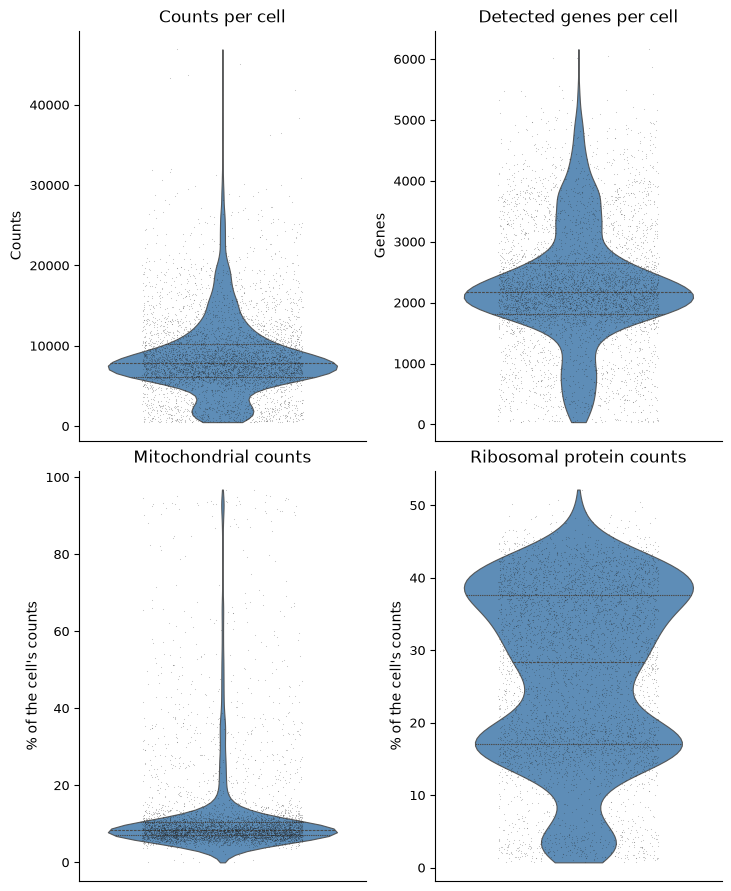

Started: 2026-11-12T17:28:57.842278Z | Wall time: 0.888 s

In [2]:
# Name the quantity that each QC column measures, and its unit.
qc_labels = {
    "RNA_nCounts": ("Counts per cell", "Counts"),
    "RNA_nFeatures": ("Detected genes per cell", "Genes"),
    "RNA_percentMito": ("Mitochondrial counts", "% of the cell's counts"),
    "RNA_percentRibo": ("Ribosomal protein counts", "% of the cell's counts"),
}
qc_cols = list(qc_labels)

# Freeze the input cells and read their QC values.
qc_cell_selection = ds.snapshot_cell_selection("I")
qc_values = ds.cells.to_pandas_dataframe(qc_cols, key="I")


# Plot the input distributions, with each named set of bounds in its own line style.
def plot_qc(bound_sets=()):
    plot = ds.plots.distribution(
        keys=qc_cols, cell_selection=qc_cell_selection, show=False
    )
    for metric, ax in plot.axes.items():
        title, unit = qc_labels[metric]
        ax.set(title=title, ylabel=unit)
        for _, bounds, style in bound_sets:
            for bound in bounds.get(metric, ()):
                if bound is not None:
                    ax.axhline(bound, color="black", linestyle=style, linewidth=1)
    if bound_sets:
        plot.figure.legend(
            [
                Line2D([], [], color="black", linestyle=style)
                for *_, style in bound_sets
            ],
            [label for label, *_ in bound_sets],
            loc="outside lower center",
            ncols=len(bound_sets),
            frameon=False,
        )
    plot.show()


# Summarize the input distributions, then plot them.
display(qc_values.describe().loc[["min", "25%", "50%", "75%", "max"]].round(1))
plot_qc()

Half of the cells have between 6,079 and 10,210 counts and between 1,816 and 2,645 detected genes. Filters act on the tails around that core. Counts reach 46,913, six times the median of 7,803. Both the count and the gene violins have a bulge of cells below their main body, down to 502 counts and 38 genes. The mitochondrial share has a median of 8.4% and a thin tail up to 96.8%: a damaged cell loses cytoplasmic RNA through its broken membrane but keeps the transcripts inside its mitochondria, so its mitochondrial share rises. The ribosomal protein share has no long upper tail; it has two main modes, one on each side of its median of 28.3%, and a smaller third mode near 3%.

## Filter with automatic bounds

`qc.auto_filter` sets each bound three median absolute deviations (MADs) from the median of the input cells. The MAD is the median distance of the values from their median, scaled to match the standard deviation of normally distributed values; unlike the standard deviation, it barely moves when extreme cells are added. Counts and detected genes get a lower and an upper bound, computed on log1p values, and the two percentages get an upper bound only. The filter warns when its bounds remove more than half of the cells, or when the bounds on counts or genes miss a second population of cells, such as a separate group above the upper bound; both happen when the empty droplets of an unfiltered matrix set the bounds. The filter returns an {term}`ArtifactRef`, a reference to the saved selection: `ds.artifacts.load` reads which cells it keeps, and `ds.artifacts.inspect` reads the bounds that it resolved.

In [3]:
# Read which input cells a selection keeps, and report the totals.
def kept_cells(selection):
    kept = pd.Series(ds.artifacts.load(selection)["values"][:], dtype=bool)
    kept = kept.loc[qc_values.index]
    print(
        f"Cells kept: {kept.sum()} of {kept.size}; "
        f"removed: {(~kept).sum()} ({(~kept).mean():.1%})"
    )
    return kept


# Count the input cells outside each bound; a cell outside several counts for each.
def removed_by_bound(bounds):
    rows = {}
    for metric, (low, high) in bounds.items():
        values = qc_values[metric]
        rows[metric] = {
            "low": low,
            "high": high,
            "removed below": 0 if low is None else (values <= low).sum(),
            "removed above": 0 if high is None else (values >= high).sum(),
        }
    return pd.DataFrame.from_dict(rows, orient="index").round(1).fillna("none")


# Compute the automatic bounds on the input cells.
automatic_selection = ds.qc.auto_filter(cell_selection=qc_cell_selection)
automatic_kept = kept_cells(automatic_selection)

# Read the bounds that the selection records, and count the cells outside each.
resolved_bounds = ds.artifacts.inspect(automatic_selection).parameters[
    "resolved_bounds"
]
automatic_bounds = {
    metric: (bound["low"], bound["high"])
    for metric, bound in resolved_bounds["all"].items()
}
removed_by_bound(automatic_bounds)

Cells kept: 4331 of 5025; removed: 694 (13.8%)


,low,high,removed below,removed above
RNA_nCounts,2476.2,24584.6,437,68
RNA_nFeatures,947.1,4975.0,449,35
RNA_percentMito,none,15.8,0,571
RNA_percentRibo,none,73.9,0,0


Started: 2026-11-12T17:28:58.733713Z | Wall time: 0.091 s

The automatic bounds keep 4,331 of the 5,025 cells and remove 694 (13.8%). Because the bounds on counts and genes are set on log1p values, each pair sits the same factor below and above the median: 2,476 and 24,585 counts lie 3.2-fold below and above the median of 7,803, and 947 and 4,975 genes 2.3-fold below and above the median of 2,171. The lower bounds remove 437 and 449 cells and the mitochondrial bound of 15.8% removes 571; these add up to more than twice the 694 removed cells, so most removed cells fail two or three of these bounds at once. The upper bounds remove only the 68 and 35 most extreme cells, and the ribosomal bound of 73.9% lies above every cell.

## Filter with manual thresholds

The PBMC analysis keeps cells with more than 1,000 and fewer than 15,000 counts, more than 500 and fewer than 4,000 detected genes, and a mitochondrial share above 0% and below 15%. `qc.filter` applies such thresholds to cell columns. Its bounds are exclusive, like those of `qc.auto_filter`: `lows=[500]` removes a cell with exactly 500 genes, which scanpy's `filter_cells(min_genes=500)` keeps. Pass `keep_bounds=True` for inclusive bounds. Apply the thresholds to the same input cells and draw both sets of bounds on the violins:

Cells kept: 3948 of 5025; removed: 1077 (21.4%)


,low,high,removed below,removed above
RNA_nCounts,1000,15000,139,458
RNA_nFeatures,500,4000,206,255
RNA_percentMito,0,15,1,603


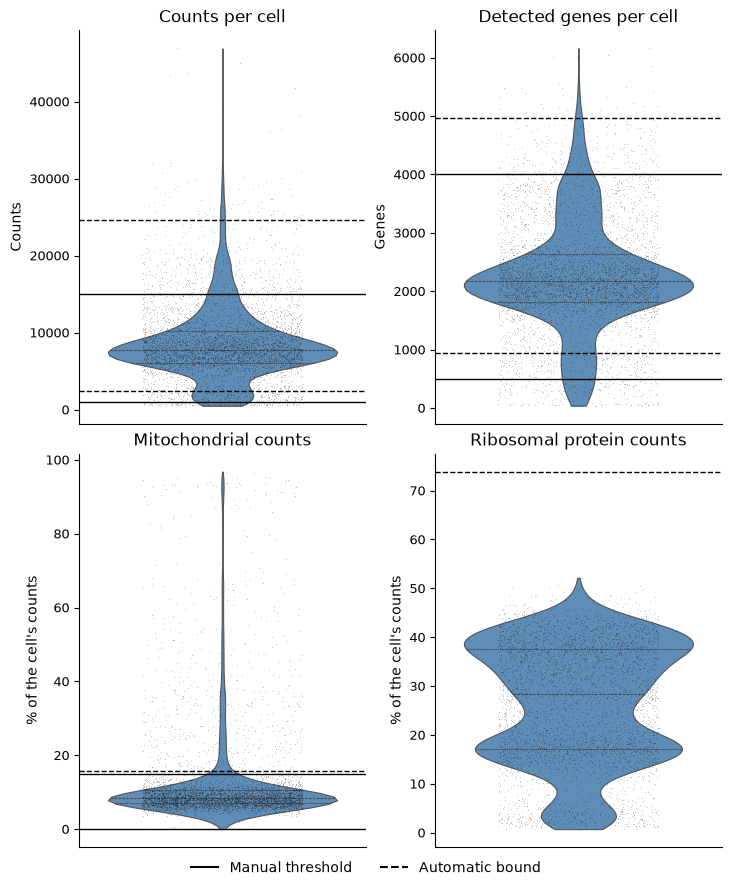

Started: 2026-11-12T17:28:58.827161Z | Wall time: 0.690 s

In [4]:
# Apply the thresholds of the PBMC analysis to the same input cells.
manual_filter = {
    "attrs": ["RNA_nCounts", "RNA_nFeatures", "RNA_percentMito"],
    "lows": [1000, 500, 0],
    "highs": [15000, 4000, 15],
}
manual_selection = ds.qc.filter(**manual_filter, cell_selection=qc_cell_selection)
manual_kept = kept_cells(manual_selection)

# Count the input cells outside each threshold.
manual_bounds = dict(
    zip(manual_filter["attrs"], zip(manual_filter["lows"], manual_filter["highs"]))
)
display(removed_by_bound(manual_bounds))

# Draw both filters on the input distributions.
plot_qc(
    [
        ("Manual threshold", manual_bounds, "-"),
        ("Automatic bound", automatic_bounds, "--"),
    ]
)

The manual thresholds keep 3,948 of the 5,025 cells and remove 1,077 (21.4%). The 15% mitochondrial threshold removes the most cells, 603, and the cap of 15,000 counts the next most, 458. Because bounds are exclusive, the mitochondrial floor of 0% removes the one cell without mitochondrial counts. On the violins, the manual cap of 15,000 counts cuts through the upper shoulder of the counts distribution, while the automatic upper bound of 24,585 sits in its thin tail; the two mitochondrial bounds nearly coincide.

## Compare the two filters

Label each input cell by the filters that keep it, count the cells of each outcome with their median QC values, and plot counts against the mitochondrial share and against detected genes:

,cells,median RNA_nCounts,median RNA_nFeatures,median RNA_percentMito,median RNA_percentRibo
Kept by both,3916,7903.0,2190.0,8.2,32.6
Removed by both,662,2041.0,760.0,29.3,5.5
Removed only by manual thresholds,415,17427.0,3950.0,7.5,19.4
Removed only by automatic bounds,32,1913.5,814.5,10.3,14.1


Removed only by manual thresholds, with 15,000 counts or more: 388


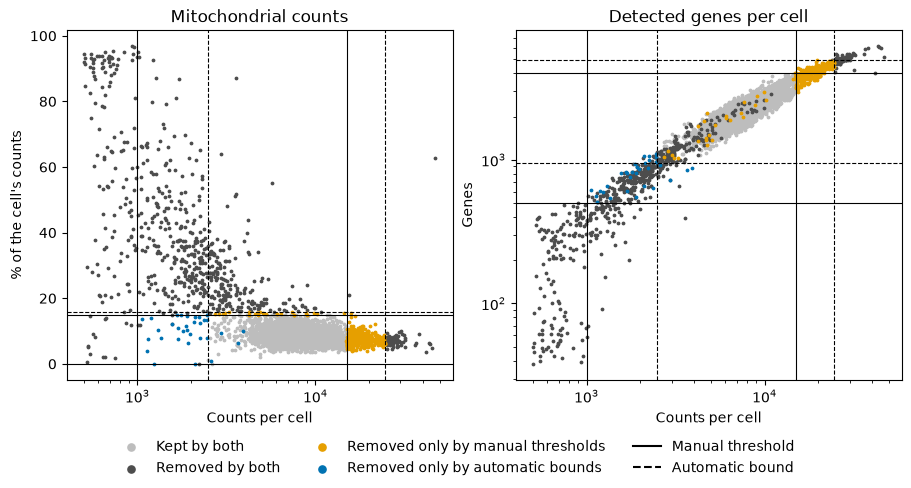

Started: 2026-11-12T17:28:59.521409Z | Wall time: 0.566 s

In [5]:
# Label each input cell by the filters that keep it.
outcomes = {
    "Kept by both": automatic_kept & manual_kept,
    "Removed by both": ~automatic_kept & ~manual_kept,
    "Removed only by manual thresholds": automatic_kept & ~manual_kept,
    "Removed only by automatic bounds": ~automatic_kept & manual_kept,
}

# Count the cells of each outcome, with their median QC values.
outcome_summary = pd.DataFrame(
    {label: qc_values[cells].median() for label, cells in outcomes.items()}
).T.add_prefix("median ")
outcome_summary.insert(0, "cells", [cells.sum() for cells in outcomes.values()])
display(outcome_summary.round(1))

# Count the manual-only removals at or above the count cap.
manual_only = outcomes["Removed only by manual thresholds"]
print(
    "Removed only by manual thresholds, with 15,000 counts or more:",
    (manual_only & (qc_values["RNA_nCounts"] >= 15000)).sum(),
)

# Plot each outcome: gray where the filters agree, orange and blue where they differ.
colors = ["#bdbdbd", "#4d4d4d", "#E69F00", "#0072B2"]
fig, axes = plt.subplots(1, 2, figsize=(9, 4.8), layout="constrained")
for ax, metric in zip(axes, ["RNA_percentMito", "RNA_nFeatures"]):
    for (label, cells), color in zip(outcomes.items(), colors):
        ax.scatter(
            qc_values["RNA_nCounts"][cells],
            qc_values[metric][cells],
            s=3,
            color=color,
            label=label,
            rasterized=True,
        )

    # Draw the manual thresholds as solid lines and the automatic bounds as dashed lines.
    for bounds, style in ((manual_bounds, "-"), (automatic_bounds, "--")):
        for value in bounds["RNA_nCounts"]:
            ax.axvline(value, color="black", linestyle=style, linewidth=0.8)
        for value in bounds[metric]:
            if value is not None:
                ax.axhline(value, color="black", linestyle=style, linewidth=0.8)
    title, unit = qc_labels[metric]
    ax.set(xscale="log", xlabel="Counts per cell", title=title, ylabel=unit)
axes[1].set_yscale("log")
handles, labels = axes[0].get_legend_handles_labels()
handles += [
    Line2D([], [], color="black"),
    Line2D([], [], color="black", linestyle="--"),
]
labels += ["Manual threshold", "Automatic bound"]
fig.legend(
    handles, labels, loc="outside lower center", ncols=3, frameon=False, markerscale=3
)
plt.show()

Both filters keep 3,916 cells and both remove 662. Most of the 662 are damaged cells in the corner of few counts and a high mitochondrial share: their median counts are 2,041 and their median mitochondrial share 29.3%, against 7,903 and 8.2% for the cells that both filters keep. Their median ribosomal protein share is 5.5%, against 32.6%, so these damaged cells form the small third mode of the ribosomal violin. The filters disagree at the two ends of the count range. The manual thresholds remove 415 cells that the automatic bounds keep: their median is 17,427 counts, and 388 of them have 15,000 counts or more. The automatic bounds remove 32 cells that the manual thresholds keep, all of them between the manual floors and the automatic lower bounds on counts or genes.

To see which cell types each filter removes, save each cell's outcome as a cell column and compare the lineage markers of the PBMC analysis across the four groups. Dot size is the share of a group's cells that detect a gene, and color is its mean expression, standardized across the groups:

group,Kept by both,Removed by both,Removed only by manual thresholds,Removed only by automatic bounds
feature,,,,
LST1,35,20,84,47
S100A8,24,17,71,50
FCGR3A,15,7,34,3
CD3D,63,20,30,3
IL7R,54,35,27,9
PPBP,1,4,1,28
PF4,0,3,0,28


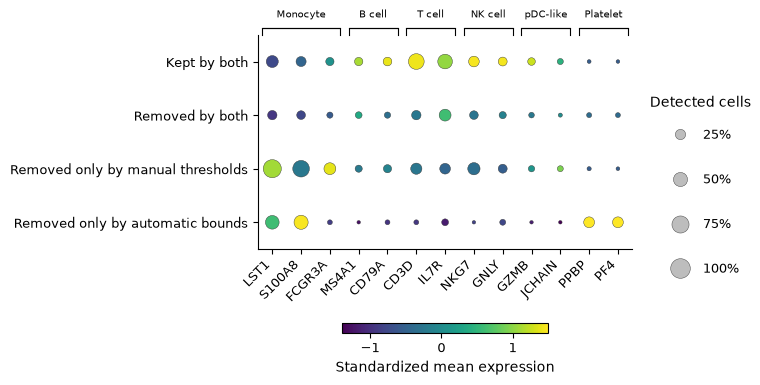

Started: 2026-11-12T17:29:00.089009Z | Wall time: 0.647 s

In [6]:
# Save each input cell's outcome as a cell column, so that plots can group cells by it.
filter_outcome = np.full(ds.cells.N, "Not in the input", dtype=object)
for label, cells in outcomes.items():
    filter_outcome[cells.index[cells]] = label
ds.cells.insert("qc_filter_outcome", filter_outcome.astype(str))

# Compare the lineage markers of the PBMC analysis across the outcomes.
marker_panel = {
    "Monocyte": ["LST1", "S100A8", "FCGR3A"],
    "B cell": ["MS4A1", "CD79A"],
    "T cell": ["CD3D", "IL7R"],
    "NK cell": ["NKG7", "GNLY"],
    "pDC-like": ["GZMB", "JCHAIN"],
    "Platelet": ["PPBP", "PF4"],
}
markers_by_outcome = ds.plots.dotplot(
    features=marker_panel,
    group_by="qc_filter_outcome",
    group_order=list(outcomes),
    standardize="feature",
    swap_axes=True,
    show=False,
)

# Show the percentage of each group's cells that detect the main lineage markers.
detected = markers_by_outcome.tables["aggregate"].pivot(
    index="feature", columns="group", values="fraction"
)
shown = ["LST1", "S100A8", "FCGR3A", "CD3D", "IL7R", "PPBP", "PF4"]
display((100 * detected.loc[shown, list(outcomes)]).round().astype(int))
markers_by_outcome.axes["dotplot"].set_ylabel("")
markers_by_outcome.show()

The cells that only the manual thresholds remove are mostly monocytes: 84% of them detect the monocyte marker LST1 and 71% S100A8, against 35% and 24% of the cells that both filters keep, while the T-cell marker CD3D falls from 63% to 30%. Monocytes hold more RNA than lymphocytes, so a fixed cap on counts removes them first. The 32 cells that only the automatic bounds remove are a mix: 28% of them detect the platelet markers PPBP and PF4, against at most 1% of the cells that both filters keep, and about half detect the monocyte markers LST1 and S100A8. Removing cells by type changes the composition that every later analysis sees, so check which populations a threshold removes before accepting it.

## Filter within each sample

Pooled bounds penalize a sample sequenced less deeply than the others: its cells sit low in the pooled distribution, so the lower bounds remove more of them. With `sample_column`, `qc.auto_filter` computes the bounds within each sample instead. This dataset is one sample, so the call below does not run here:

```python
# Compute the bounds within each sample of a sample_id column.
sample_selection = ds.qc.auto_filter(
    cell_selection=qc_cell_selection,
    sample_column="sample_id",
)
```

A sample with fewer cells than `min_cells_per_sample`, `20` by default, keeps all of them, with a warning, because its bounds cannot be estimated reliably. The RNA recipe takes the same option, as `ds.pipeline.rna(filtering={"sample_column": "sample_id"})`. With cell hashing, the recipe's `hashing` stage keeps the cells of exactly one hashtag and computes the bounds within each hashtag unless `filtering` names a `sample_column`, as [the HTO demultiplexing tutorial](hto_demultiplexing.ipynb) shows.

## Filter imported QC columns

`qc.auto_filter` gives each metric a policy: which bounds apply, and whether they are computed on log1p or raw values. The columns that CyteArc wrote get the policies used above. A QC column imported from another tool gets its policy from the end of its name, with a warning: a name ending in `nCounts` or `nFeatures` is treated as counts, one ending in `percentMito` or `percentRibo` as a percentage, and any other name gets two-sided bounds on raw values. Scanpy's `total_counts` and `pct_counts_mt` fall in the last group, so set their policies with `metric_policies`. To show the call, export 500 input cells with scanpy's column names and import them into a new store:

In [7]:
# Export 500 random input cells with their QC columns under scanpy's names.
import_rows = np.random.default_rng(42).choice(
    np.flatnonzero(ds.cells.fetch_all("I")), size=500, replace=False
)
ds.cells.insert("qc_import_example", np.isin(np.arange(ds.cells.N), import_rows))
qc_export = ds.to_anndata(cell_key="qc_import_example")
qc_export.obs = qc_export.obs[["RNA_nCounts", "RNA_percentMito"]].rename(
    columns={"RNA_nCounts": "total_counts", "RNA_percentMito": "pct_counts_mt"}
)

# Drop the store's feature key, which a scanpy file lacks, and write the file.
qc_export.var = qc_export.var.drop(columns="I")
qc_h5ad = Path(workspace.name) / "qc_metrics.h5ad"
qc_export.write_h5ad(qc_h5ad)

# Import the file into a new store that keeps all 500 cells for the filter.
qc_inspection = cytearc.inspect_h5ad(str(qc_h5ad))
with closing(cytearc.H5adReader.from_inspect(qc_inspection)) as qc_reader:
    cytearc.H5adToZarr(
        qc_reader, zarr_loc=str(qc_h5ad.with_suffix(".zarr")), nthreads=4
    ).dump()
imported_qc = cytearc.DataStore(
    str(qc_h5ad.with_suffix(".zarr")), min_features_per_cell=-1, nthreads=4
)

# Show the imported QC columns.
imported_qc.cells.to_pandas_dataframe(["total_counts", "pct_counts_mt"]).head()

,total_counts,pct_counts_mt
0,1860.0,41.666667
1,11890.0,11.177460
2,10794.0,7.735779
3,6518.0,7.241485
4,7827.0,7.716877


Started: 2026-11-12T17:29:00.738247Z | Wall time: 2.303 s

In [8]:
# Bound log1p counts on both sides and the mitochondrial share from above.
imported_selection = imported_qc.qc.auto_filter(
    attrs=["total_counts", "pct_counts_mt"],
    metric_policies={
        "total_counts": {"transform": "log1p", "bound_direction": "two_sided"},
        "pct_counts_mt": {"transform": "identity", "bound_direction": "upper"},
    },
)
imported_mask = imported_qc.artifacts.load(imported_selection)["values"][:]
print(f"Imported cells kept: {imported_mask.sum()} of {imported_qc.cells.N}")

# Show each column's policy and bounds, on the column's own scale.
imported_bounds = imported_qc.artifacts.inspect(imported_selection).parameters[
    "resolved_bounds"
]["all"]
imported_table = pd.DataFrame(imported_bounds).T[
    ["transform", "bound_direction", "low", "high"]
]
imported_table.astype({"low": float, "high": float}).round(1).fillna("none")

Imported cells kept: 444 of 500


,transform,bound_direction,low,high
total_counts,log1p,two_sided,2610.6,25285.7
pct_counts_mt,identity,upper,none,15.2


Started: 2026-11-12T17:29:03.043213Z | Wall time: 0.094 s

The bounds, 2,611 to 25,286 counts and a mitochondrial share below 15.2%, keep 444 of the 500 cells. They differ slightly from the bounds of all 5,025 input cells, 2,476 to 24,585 counts and 15.8%, because the median and MAD of a random sample of 500 cells differ from those of the full input. A policy with `bound_direction="lower"` removes only low-count cells and leaves the high-count cells for review, and `metric_policies` also applies within each sample of a `sample_column`.

## Measure other gene families

The mitochondrial and ribosomal percentages count the genes whose names match `^MT-` and `^RPS|^RPL|^MRPS|^MRPL`, ignoring case; the ribosomal pattern matches ribosomal protein genes, not ribosomal RNA. Features named by Ensembl IDs match neither pattern, so check a store's feature names before reading a zero percentage. Both columns are computed when a store is first opened, replacing any imported column of the same name, and stay fixed: a later open with a different `mito_pattern` or `ribo_pattern` raises an error. For another gene family, select its genes and compute their share of each cell's counts with `qc.feature_percentage`, which saves the shares as a result rather than as a cell column. Most genes whose names start with `HSP` encode heat-shock proteins, which rise in stressed cells:

In [9]:
# Select the genes whose names start with HSP.
feature_names = ds.RNA.feats.fetch_all("names").astype(str)
stress_mask = np.char.startswith(feature_names, "HSP")
stress_features = ds.features.snapshot(from_assay="RNA", mask=stress_mask)
print(f"Genes selected: {stress_mask.sum()}")

# Compute their share of the counts of each cell that passes the manual thresholds.
stress_percentage = ds.qc.feature_percentage(manual_selection, stress_features)
stress_values = np.asarray(ds.artifacts.load(stress_percentage)["values"][:])
pd.Series(stress_values, name="HSP genes (% of counts)").describe().round(2)

Genes selected: 34


count    3948.00
mean        0.33
std         0.13
min         0.00
25%         0.24
50%         0.31
75%         0.40
max         1.53
Name: HSP genes (% of counts), dtype: float64

Started: 2026-11-12T17:29:03.139488Z | Wall time: 0.367 s

The 34 genes with the HSP prefix take a median of 0.31% of the counts of a cell that passes the manual thresholds, and at most 1.53%, about five times the median. To filter on such a percentage, pass the result to `ds.select_cells` with a `high` bound. Excluding gene families from the highly variable genes is a separate choice, covered in [the feature selection tutorial](feature_selection.ipynb).

## Score doublets

A doublet is a droplet that captured two cells, so one barcode holds the RNA of both. A doublet of two cell types can show the markers of both and look like a cell state of its own; a doublet of two cells of one type looks like one cell with more RNA.

CyteArc scores doublets as Scrublet does [@Wolock_2019]. Scoring simulates doublets by adding the counts of two cells of the same sample and gives each cell the probability that it is a doublet from the share of simulated doublets among its nearest neighbors in PCA space; the {ref}`methods page <doublet_method>` gives the details. Doublets form only within one capture, so name each cell's 10x channel or lane with `doublets={"sample_column": ...}` when cells come from several; this dataset is one capture. `qc.doublets` takes a neighbor graph, onto whose PCA it projects the simulated doublets, and the graph's clusters, so run the RNA recipe on the cells that pass the manual thresholds, with the settings of the PBMC analysis: 500 highly variable genes, 15 principal components and Leiden resolution 0.5, without cell-cycle scoring or markers. The recipe takes the selection as `cells`, analyzes exactly those cells and returns a {term}`PipelineRun`. Indexing the run by a result name, as in `doublet_run["doublets"]`, returns a reference to that saved result, and `doublet_run.cells` reads per-cell values of the run, such as each cell's cluster and doublet call:

In [10]:
# Run the PBMC analysis on the manual selection and score its doublets.
doublet_run = ds.pipeline.rna(
    cells=manual_selection,
    hvg={"top_n": 500},
    pca={"dims": 15},
    leiden={"partitions": [0.5]},
    cell_cycle=False,
    doublets=True,
    markers=False,
)

# Read the saved doublet scores and each analyzed cell's call.
doublets = doublet_run["doublets"]
called = np.asarray(doublet_run.cells.fetch("predicted_doublet"))
print(f"Predicted doublets: {called.sum()} of {called.size} cells")

# Compare the counts of the predicted doublets with those of the other cells.
run_values = qc_values.loc[np.flatnonzero(doublet_run.cells.fetch_all("I"))]
run_counts = run_values["RNA_nCounts"].to_numpy()
print(
    f"Median counts: {np.median(run_counts[called]):,.0f} in the predicted doublets, "
    f"{np.median(run_counts[~called]):,.0f} in the other cells"
)

# Count doublets and automatically removed cells per cluster, with median QC values.
per_cell = run_values.assign(
    cluster=doublet_run.cells.fetch("clusters"),
    doublet=called,
    removed=~automatic_kept.loc[run_values.index].to_numpy(),
)
per_cluster = per_cell.groupby("cluster").agg(
    **{
        "cells": ("doublet", "size"),
        "predicted doublets": ("doublet", "sum"),
        "removed by automatic bounds": ("removed", "sum"),
        "median genes": ("RNA_nFeatures", "median"),
        "median ribosomal protein counts (%)": ("RNA_percentRibo", "median"),
    }
)
per_cluster.round(1)

Predicted doublets: 17 of 3948 cells
Median counts: 11,327 in the predicted doublets, 7,876 in the other cells


,cells,predicted doublets,removed by automatic bounds,median genes,median ribosomal protein counts (%)
cluster,,,,,
1,1217,0,8,1958.0,39.7
2,704,8,15,2988.5,16.4
3,528,1,0,2225.0,28.0
4,474,1,0,2373.5,35.6
5,283,2,0,2270.0,16.8
6,256,4,0,1928.5,30.8
7,239,1,0,2290.0,33.2
8,166,0,0,2118.0,39.4
9,29,0,0,2432.0,25.9


Started: 2026-11-12T17:29:03.509224Z | Wall time: 89.936 s

The run calls 17 of the 3,948 cells doublets. The predicted doublets carry more RNA: their median of 11,327 counts is 1.4 times the 7,876 of the other cells. The run's cells and settings are those of [the PBMC analysis](scrna_seq.ipynb), and so are its 12 clusters, which that page names from their markers: T cells in clusters 1, 3, 4 and 8, CD14 monocytes in 2 and other monocytes, which express FCGR3A, in 10, NK cells in 5 and 9, B cells in 6 and 7, pDC-like cells in 11 and platelets in 12. Cluster 2 holds 8 of the 17 predicted doublets and cluster 6 holds 4; no cluster is made of doublets.

The table also explains the two main modes of the ribosomal protein share and the cells that only the automatic bounds remove. The ribosomal protein share follows cell type: its median is 14.3% to 16.8% in the monocyte and NK clusters 2, 5 and 10 and 35.6% to 39.7% in T-cell clusters 1, 4 and 8, so these cells form the modes near 17% and 38% of its violin, while T-cell cluster 3 sits between them, at 28.0%. The platelets of cluster 12 have a median of 695 detected genes, below the automatic lower bound of 947, so the automatic bounds remove 9 of the 12 platelets. The other cells that only the automatic bounds remove are 15 of the 704 cells of CD14 monocyte cluster 2 and 8 of the 1,217 cells of T-cell cluster 1.

Plot the clusters beside the doublet scores:

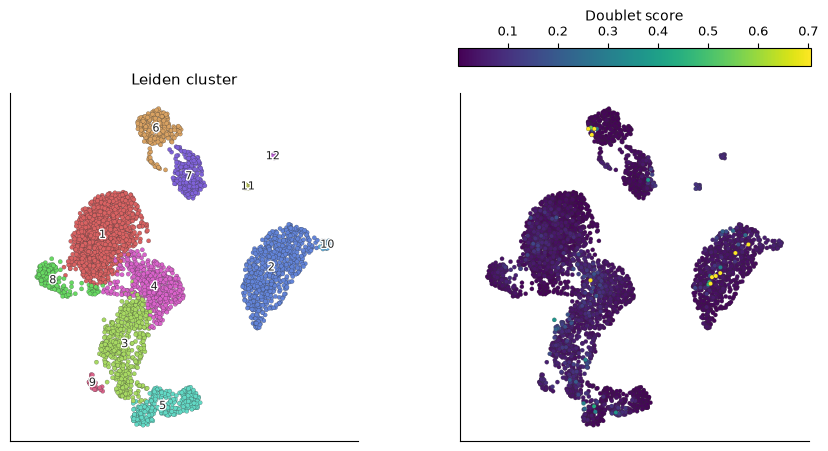

Started: 2026-11-12T17:30:33.447242Z | Wall time: 0.447 s

In [11]:
# Show where high doublet scores fall among the clusters, drawing the highest on top.
ds.plots.embedding(
    run=doublet_run,
    color_by=[
        CellField("clusters", kind="categorical", label="Leiden cluster"),
        CellField("doublet_score", label="Doublet score"),
    ],
    sort_values=True,
    legend_loc="on_data",
    figsize=(9, 4.4),
)

Most of the highest scores sit inside clusters 2 and 6 rather than between clusters. The threshold that turns scores into calls comes from the simulated doublets: those of two cells of one type look like singlets and score low, those of two types score high, and the threshold is the minimum between the two modes of their scores. Plot the scores of the simulated doublets and of the cells, with the threshold as a dashed line:

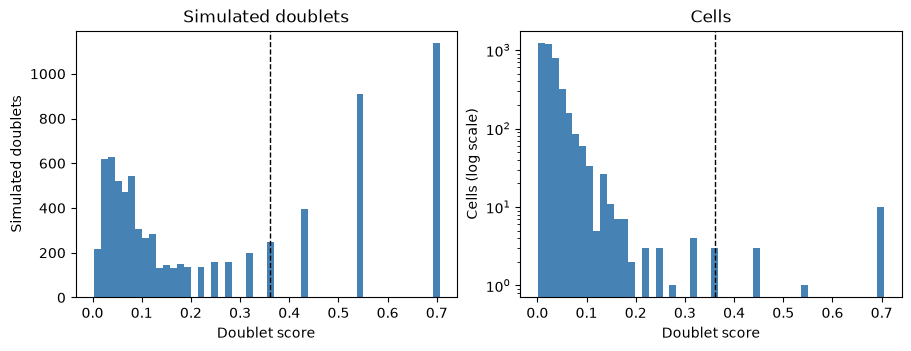

Started: 2026-11-12T17:30:33.897170Z | Wall time: 0.855 s

In [12]:
# Read the scores of the cells and of the simulated doublets, and the run's one sample.
payload = ds.artifacts.load(doublets)
(sample,) = payload.attrs["samples"]

# Compare both score distributions, with a log scale for the rare high-scoring cells.
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharex=True, layout="constrained")
axes[0].hist(payload["simulated_scores"][:], bins=50, color="steelblue")
axes[0].set(title="Simulated doublets", ylabel="Simulated doublets")
axes[1].hist(payload["values"][:], bins=50, color="steelblue")
axes[1].set(title="Cells", ylabel="Cells (log scale)", yscale="log")
for ax in axes:
    ax.axvline(sample["threshold"], color="black", linestyle="--", linewidth=1)
    ax.set_xlabel("Doublet score")
plt.show()

The high scores take only a few values because a cell's score depends only on how many of its 90 nearest neighbors are simulated doublets. The `samples` attribute of the scores records how each sample's threshold was chosen and what it calls:

In [13]:
# Show how the threshold was chosen and what it calls.
display(
    pd.Series(
        {
            key: sample[key]
            for key in (
                "cells",
                "simulatedDoublets",
                "adjustedNeighbors",
                "threshold",
                "thresholdMethod",
                "predictedDoublets",
                "detectableDoubletFraction",
                "estimatedDoubletRate",
            )
        }
    )
)

# Count the simulated doublets among the neighbors of each predicted doublet.
simulated_neighbors = np.rint(payload["raw_scores"][:] * sample["adjustedNeighbors"])
predicted = payload["predicted_doublets"][:]
print(
    f"Simulated doublets among the {sample['adjustedNeighbors']} neighbors of a "
    f"predicted doublet: {simulated_neighbors[predicted].min():.0f} to "
    f"{simulated_neighbors[predicted].max():.0f}"
)

cells                            3948
simulatedDoublets                7896
adjustedNeighbors                  90
threshold                    0.360997
thresholdMethod               minimum
predictedDoublets                  17
detectableDoubletFraction    0.340299
estimatedDoubletRate         0.012654
dtype: object

Simulated doublets among the 90 neighbors of a predicted doublet: 87 to 90


Started: 2026-11-12T17:30:34.754516Z | Wall time: 0.013 s

The simulated scores have a valley, so the method is `minimum`; scores without a valley get Otsu's threshold, `otsu`. The threshold of 0.361 calls a cell a doublet when at least 87 of its 90 nearest neighbors are simulated doublets. Only 34% of the simulated doublets score above the threshold; the others pair two cells similar enough to pass as one. Scrublet's estimate of the doublet rate divides the share of cells called by that detectable fraction, which gives 1.3%, a third of the 3.9% multiplet rate that the 10x Genomics user guide for v3 chemistry lists for about 5,000 recovered cells. The cap of 15,000 counts removed 458 cells before scoring, and any doublets among them are missing from the estimate.

For your own data, compare the estimate with the rate that the user guide of your kit lists for the number of cells recovered. When the two disagree, or the method is `otsu`, review the histograms and pass a `threshold` to `qc.doublets`, or `doublets={"threshold": ...}` to the RNA recipe. `doublet_run.report()` lists each sample's threshold and calls beside the summaries of the run's other stages.

## Keep the singlets

Doublet scoring removes no cells. Select the cells that were not called doublets:

In [14]:
# Keep the cells that were not called doublets.
singlets = ds.select_cells(doublets, value="predicted_doublets", include=[False])
print(f"Singlets: {np.asarray(ds.artifacts.load(singlets)['values'][:]).sum()}")

Singlets: 3931


Started: 2026-11-12T17:30:34.769593Z | Wall time: 0.040 s

The 3,931 singlets, the 3,948 scored cells without the 17 predicted doublets, form a new cell selection. `ds.select_cells` reads one per-cell array of a result, here `predicted_doublets`, and keeps the cells whose value `include` lists. For numeric values, `low` and `high` set the range to keep: `ds.select_cells(doublets, high=0.3, keep_bounds=True)` keeps the cells that score at most `0.3`. {ref}`Read per-cell values <cell_aligned_kinds>` lists the results and arrays that `ds.select_cells` reads. Pass the singlets as `cells` to the RNA recipe, as above, to analyze them.

## Filter ATAC cells

Opening a store with an ATAC assay computes each cell's fragment or cut-site count and the number of peaks with at least one count. The ATAC recipe, `ds.pipeline.atac`, filters cells on these two columns, then `features.prevalent_peaks` keeps the peaks with the highest summed TF-IDF values across the remaining cells for {term}`LSI` and the neighbor graph, as [the scATAC-seq tutorial](scatac_seq.ipynb) shows. CyteArc does not compute the fraction of reads in peaks (FRiP) or transcription start site (TSS) enrichment; import them as cell metadata from another tool to filter on them.

## Filter antibody and multimodal assays

Antibody panels often include isotype controls, which the ADT recipe, `ds.pipeline.adt`, leaves out of its panel by default: the antibodies whose names contain "isotype", "control" or "ctrl", in any case. `panel={"exclude": ...}` sets another pattern. RNA, ADT and HTO assays share one cell table, so one cell selection serves every assay: `ds.pipeline.adt(cells=rna_run)` analyzes the cells that an RNA run kept without filtering them again. [The HTO demultiplexing tutorial](hto_demultiplexing.ipynb) covers hashtag demultiplexing.